# Late or On Time? A Risk Score for the Delivery App
*Prepared by Calzado*

> **Question from the company:** *"Who should see the 'Heads up! Your order may arrive late' message?"*

My plan is simple: learn from the 440 deliveries we already know the outcome of, give every new order a **lateness risk score** (a probability), and pick the score above which the warning is worth showing. The model is a logistic regression, and I deliberately keep the inputs in their **original units** (kilometres, kilograms, years) so the coefficients can be read directly by non-technical staff.

---
## Part A: Framing the decision

Every time the app decides whether to warn, one of four things happens:

| | Order actually late | Order actually on time |
|---|---|---|
| **Warning shown** | Good call: customer was prepared | Unnecessary warning: mild annoyance |
| **No warning** | Missed late delivery: customer blindsided | Good call |

I treat a **missed late delivery as about three times as bad** as an unnecessary warning. A blindsided customer may complain, cancel or leave a bad review; a customer who was warned but got their food on time is mostly just pleasantly surprised. This 3:1 weighting is a business assumption, and I use it later when choosing the cutoff.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, roc_auc_score)

SEED = 42
sns.set_theme(style="whitegrid", palette="Set2")

---
## Part B: Getting to know the data

In [2]:
raw = pd.read_csv("deliveries.csv")
print(f"{raw.shape[0]} deliveries, {raw.shape[1]} columns")
raw.sample(5, random_state=SEED)

440 deliveries, 8 columns


,delivery_id,distance_km,package_weight_kg,rush_hour,is_raining,driver_experience_years,vehicle_type,delivered_late
265,D527,16.0,4.6,0,0,5.3,car,1
78,D557,9.6,11.0,1,0,2.0,motorcycle,0
347,D372,7.8,1.5,1,0,0.8,motorcycle,1
255,D470,8.0,8.5,0,0,10.2,motorcycle,0
327,D245,13.9,1.1,0,1,2.0,van,1


In [3]:
checks = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique_values": raw.nunique(),
})
checks

,dtype,missing,unique_values
delivery_id,object,0,440
distance_km,float64,0,172
package_weight_kg,float64,0,104
rush_hour,int64,0,2
is_raining,int64,0,2
driver_experience_years,float64,0,104
vehicle_type,object,0,3
delivered_late,int64,0,2


In [4]:
n_dup_ids = raw["delivery_id"].duplicated(keep=False).sum()
print(f"Rows sharing a delivery_id with another row: {n_dup_ids}")
print(f"Total missing cells: {raw.isna().sum().sum()}")
print()
balance = raw["delivered_late"].map({0: "on time", 1: "late"}).value_counts()
print(balance)
print(f"\nLate rate: {raw['delivered_late'].mean():.1%}")

Rows sharing a delivery_id with another row: 0
Total missing cells: 0

delivered_late
on time    264
late       176
Name: count, dtype: int64

Late rate: 40.0%


**What I found:** every `delivery_id` is unique and no cell is empty, so nothing needs cleaning. **40% of deliveries were late**, so if we warned nobody we would be right 60% of the time, which is the floor any useful model has to beat.

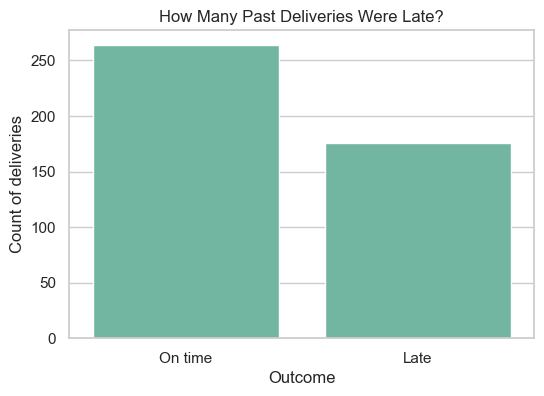

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x=raw["delivered_late"].map({0: "On time", 1: "Late"}), ax=ax, order=["On time", "Late"])
ax.set_title("How Many Past Deliveries Were Late?")
ax.set_xlabel("Outcome")
ax.set_ylabel("Count of deliveries")
plt.show()

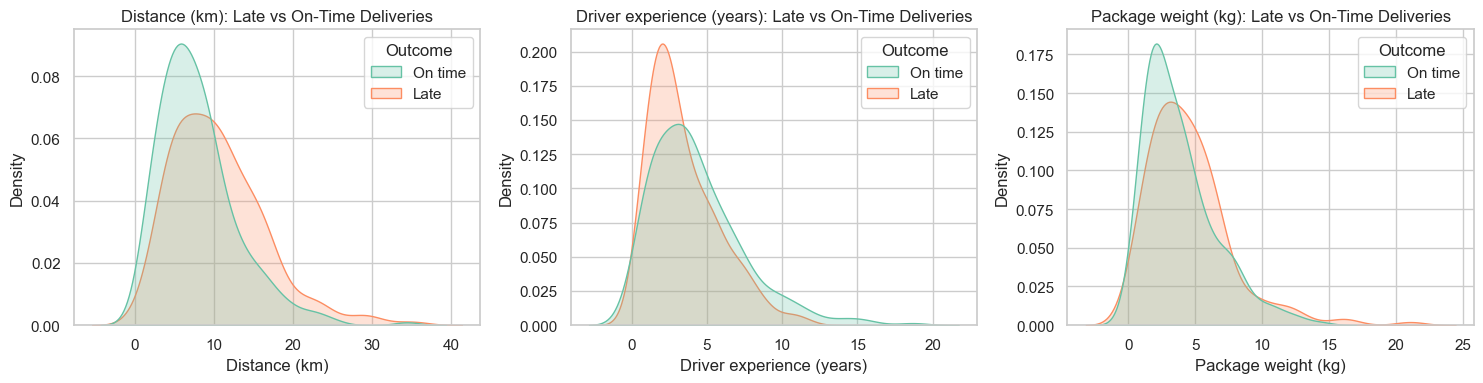

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, unit in zip(axes,
                         ["distance_km", "driver_experience_years", "package_weight_kg"],
                         ["Distance (km)", "Driver experience (years)", "Package weight (kg)"]):
    sns.kdeplot(data=raw, x=col, hue=raw["delivered_late"].map({0: "On time", 1: "Late"}),
                common_norm=False, fill=True, ax=ax)
    ax.set_title(f"{unit}: Late vs On-Time Deliveries")
    ax.set_xlabel(unit)
    ax.set_ylabel("Density")
    ax.get_legend().set_title("Outcome")
plt.tight_layout()
plt.show()

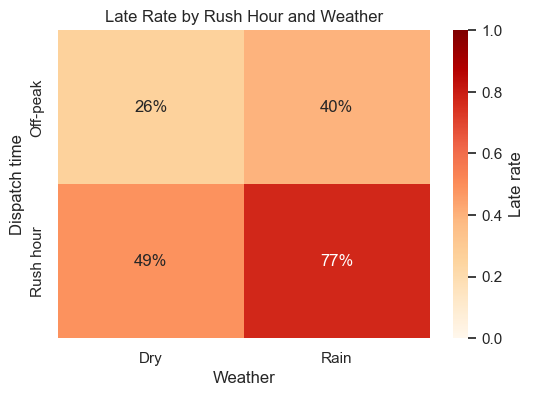

In [7]:
combo = (raw.assign(rush=raw["rush_hour"].map({0: "Off-peak", 1: "Rush hour"}),
                    weather=raw["is_raining"].map({0: "Dry", 1: "Rain"}))
            .pivot_table(index="rush", columns="weather", values="delivered_late", aggfunc="mean"))
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(combo, annot=True, fmt=".0%", cmap="OrRd", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "Late rate"})
ax.set_title("Late Rate by Rush Hour and Weather")
ax.set_xlabel("Weather")
ax.set_ylabel("Dispatch time")
plt.show()

Rush hour and rain clearly stack: dry off-peak orders are late far less often than rainy rush-hour orders. Late deliveries also tend to be longer trips and to have less experienced drivers.

---
## Part C: Splitting the data

I hold out data in two stages, stratifying on the outcome both times so every piece keeps the 40% late rate:
* **70% training**: the model learns from these.
* **15% validation**: used only to choose the warning cutoff.
* **15% test**: locked away until the very end for one honest final score.

In [8]:
train_df, holdout_df = train_test_split(raw, test_size=0.30, stratify=raw["delivered_late"], random_state=SEED)
valid_df, test_df = train_test_split(holdout_df, test_size=0.50, stratify=holdout_df["delivered_late"], random_state=SEED)

for name, part in [("train", train_df), ("valid", valid_df), ("test", test_df)]:
    print(f"{name:>5}: {len(part):3d} rows, late rate {part['delivered_late'].mean():.1%}")

train: 308 rows, late rate 39.9%
valid:  66 rows, late rate 40.9%
 test:  66 rows, late rate 39.4%


---
## Part D: Preparing the inputs

* `delivery_id` stays in each table so predictions can be matched back, but it is never shown to the model.
* `vehicle_type` becomes 0/1 columns. The list of vehicle categories is **learned from the training set only** and then applied to every other table, so validation, test and new data are encoded in exactly the same way (an unseen vehicle type would simply get zeros). **Motorcycle** is the baseline, so the `car` and `van` coefficients mean "compared with a motorcycle".
* I do **not** rescale the numbers. Logistic regression does not need scaling to work, and leaving the units alone lets me say things like "each extra kilometre…" directly.

In [9]:
TARGET = "delivered_late"
NUMERIC = ["distance_km", "package_weight_kg", "rush_hour", "is_raining", "driver_experience_years"]
BASELINE_VEHICLE = "motorcycle"

vehicle_levels = sorted(train_df["vehicle_type"].unique())          # learned from training data only
dummy_levels = [v for v in vehicle_levels if v != BASELINE_VEHICLE]
print("Vehicle levels seen in training:", vehicle_levels)
print("Dummy columns created:", ["is_" + v for v in dummy_levels])

def make_inputs(frame):
    out = frame[NUMERIC].copy()
    for v in dummy_levels:
        out["is_" + v] = (frame["vehicle_type"] == v).astype(int)
    return out

X_tr, y_tr = make_inputs(train_df), train_df[TARGET]
X_va, y_va = make_inputs(valid_df), valid_df[TARGET]
X_te, y_te = make_inputs(test_df), test_df[TARGET]
X_tr.head()

Vehicle levels seen in training: ['car', 'motorcycle', 'van']
Dummy columns created: ['is_car', 'is_van']


,distance_km,package_weight_kg,rush_hour,is_raining,driver_experience_years,is_car,is_van
208,7.8,2.9,0,1,4.4,0,0
181,10.7,2.4,1,0,8.7,0,1
305,7.4,2.3,1,0,9.6,1,0
266,6.4,5.0,0,0,3.2,1,0
162,14.1,2.5,0,0,6.1,0,1


---
## Part E: Fitting the model

In [10]:
clf = LogisticRegression(max_iter=5000, random_state=SEED)
clf.fit(X_tr, y_tr)

effects = pd.DataFrame({"coef": clf.coef_[0]}, index=X_tr.columns)
effects["odds_multiplier"] = np.exp(effects["coef"])
effects["pct_change_in_odds"] = (effects["odds_multiplier"] - 1) * 100
print(f"Intercept: {clf.intercept_[0]:.3f}")
effects.round(3).sort_values("coef", ascending=False)

Intercept: -2.401


,coef,odds_multiplier,pct_change_in_odds
rush_hour,1.188,3.280,227.982
is_van,1.010,2.745,174.526
is_raining,0.787,2.198,119.758
is_car,0.238,1.268,26.813
distance_km,0.120,1.128,12.777
package_weight_kg,0.079,1.083,8.264
driver_experience_years,-0.120,0.887,-11.271


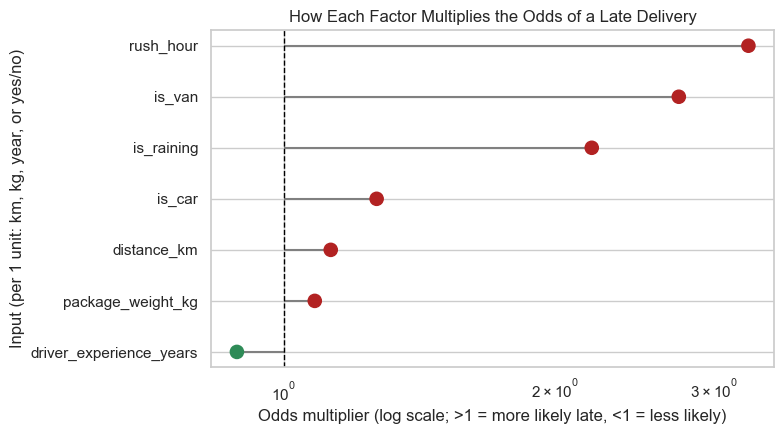

In [11]:
ordered = effects.sort_values("odds_multiplier")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(ordered["odds_multiplier"], ordered.index, s=90,
           c=np.where(ordered["odds_multiplier"] > 1, "firebrick", "seagreen"), zorder=3)
ax.hlines(ordered.index, 1, ordered["odds_multiplier"], color="grey", zorder=2)
ax.axvline(1, color="black", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_title("How Each Factor Multiplies the Odds of a Late Delivery")
ax.set_xlabel("Odds multiplier (log scale; >1 = more likely late, <1 = less likely)")
ax.set_ylabel("Input (per 1 unit: km, kg, year, or yes/no)")
plt.tight_layout()
plt.show()

In [12]:
print(f"ROC-AUC on training:   {roc_auc_score(y_tr, clf.predict_proba(X_tr)[:, 1]):.3f}")
print(f"ROC-AUC on validation: {roc_auc_score(y_va, clf.predict_proba(X_va)[:, 1]):.3f}")

ROC-AUC on training:   0.785
ROC-AUC on validation: 0.823


The training and validation AUC are close, so the model is not simply memorising the training orders.

---
## Part F: Choosing when to warn

I compare four cutoffs on the **validation** set: 0.35, 0.45, 0.50 (the default) and 0.55. For each I count unnecessary warnings and missed late deliveries, then compute a **weighted cost** = 1 x unnecessary warnings + 3 x missed late deliveries (the 3:1 assumption from Part A).

In [13]:
p_va = clf.predict_proba(X_va)[:, 1]
COST_FALSE_ALARM, COST_MISSED = 1, 3

def score_cutoff(cut, y_true, p):
    flag = (p >= cut).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, flag, labels=[0, 1]).ravel()
    return pd.Series({
        "cutoff": cut,
        "share_warned": flag.mean(),
        "unnecessary_warnings": fp,
        "missed_late": fn,
        "precision": tp / (tp + fp) if (tp + fp) else np.nan,
        "recall": tp / (tp + fn),
        "weighted_cost": COST_FALSE_ALARM * fp + COST_MISSED * fn,
    })

options = pd.DataFrame([score_cutoff(c, y_va, p_va) for c in [0.35, 0.45, 0.50, 0.55]])
options.style.format({"share_warned": "{:.0%}", "precision": "{:.2f}", "recall": "{:.2f}",
                      "cutoff": "{:.2f}", "unnecessary_warnings": "{:.0f}",
                      "missed_late": "{:.0f}", "weighted_cost": "{:.0f}"}) \
       .highlight_min(subset=["weighted_cost"], color="lightgreen")

,cutoff,share_warned,unnecessary_warnings,missed_late,precision,recall,weighted_cost
0,0.35,55%,15,6,0.58,0.78,33
1,0.45,39%,6,7,0.77,0.74,27
2,0.50,32%,4,10,0.81,0.63,34
3,0.55,21%,1,14,0.93,0.48,43


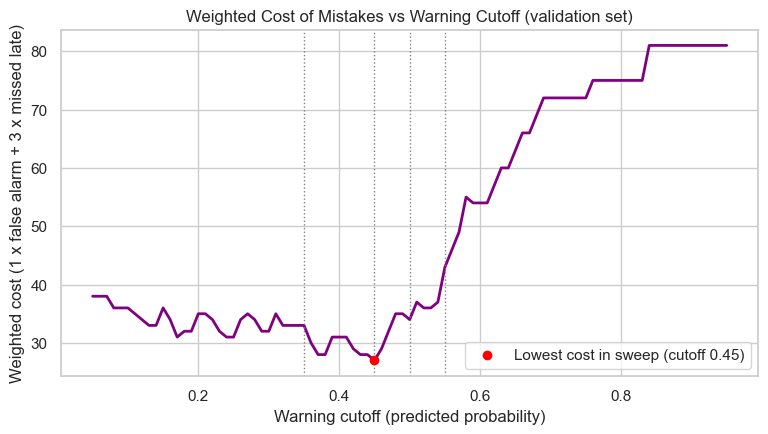

In [14]:
sweep = pd.DataFrame([score_cutoff(c, y_va, p_va) for c in np.linspace(0.05, 0.95, 91)])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(sweep["cutoff"], sweep["weighted_cost"], color="purple", linewidth=2)
for c in options["cutoff"]:
    ax.axvline(c, color="grey", linestyle=":", linewidth=1)
best_sweep = sweep.loc[sweep["weighted_cost"].idxmin()]
ax.scatter(best_sweep["cutoff"], best_sweep["weighted_cost"], color="red", zorder=3,
           label=f"Lowest cost in sweep (cutoff {best_sweep['cutoff']:.2f})")
ax.set_title("Weighted Cost of Mistakes vs Warning Cutoff (validation set)")
ax.set_xlabel("Warning cutoff (predicted probability)")
ax.set_ylabel("Weighted cost (1 x false alarm + 3 x missed late)")
ax.legend()
plt.show()

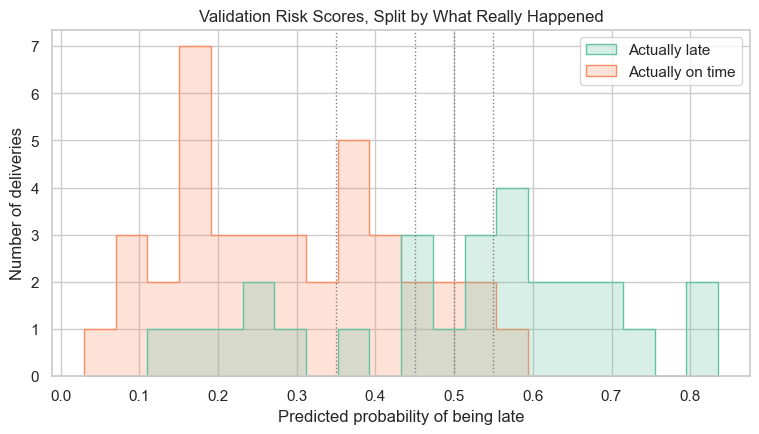

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(x=p_va, hue=y_va.map({0: "Actually on time", 1: "Actually late"}).values,
             bins=20, element="step", stat="count", ax=ax)
for c in options["cutoff"]:
    ax.axvline(c, color="grey", linestyle=":", linewidth=1)
ax.set_title("Validation Risk Scores, Split by What Really Happened")
ax.set_xlabel("Predicted probability of being late")
ax.set_ylabel("Number of deliveries")
plt.show()

In [16]:
WARN_CUTOFF = float(options.loc[options["weighted_cost"].idxmin(), "cutoff"])
print(f"Selected cutoff: {WARN_CUTOFF:.2f}")

Selected cutoff: 0.45


The cutoff with the lowest weighted cost among the four candidates is selected automatically above; the reasoning is discussed in the report at the end.

---
## Part G: The one-time test

In [17]:
p_te = clf.predict_proba(X_te)[:, 1]
warn_te = (p_te >= WARN_CUTOFF).astype(int)

cm_te = confusion_matrix(y_te, warn_te, labels=[0, 1])
tn, fp, fn, tp = cm_te.ravel()
print(f"Caught late deliveries (TP):   {tp}")
print(f"Unnecessary warnings (FP):     {fp}")
print(f"Missed late deliveries (FN):   {fn}")
print(f"Correctly not warned (TN):     {tn}")
print()
print(f"Precision = {precision_score(y_te, warn_te):.3f}  (of the warnings shown, share that were truly late)")
print(f"Recall    = {recall_score(y_te, warn_te):.3f}  (of the truly late orders, share that got a warning)")

Caught late deliveries (TP):   15
Unnecessary warnings (FP):     9
Missed late deliveries (FN):   11
Correctly not warned (TN):     31

Precision = 0.625  (of the warnings shown, share that were truly late)
Recall    = 0.577  (of the truly late orders, share that got a warning)


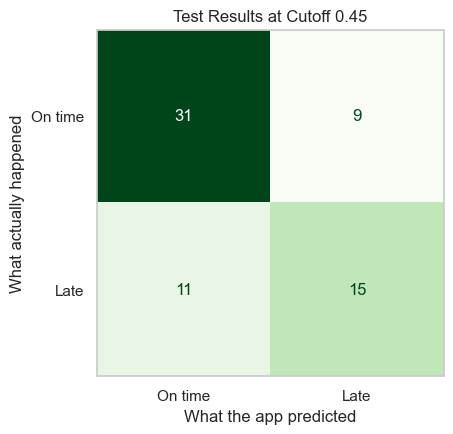

In [18]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm_te, display_labels=["On time", "Late"]).plot(ax=ax, cmap="Greens", colorbar=False)
ax.set_title(f"Test Results at Cutoff {WARN_CUTOFF:.2f}")
ax.set_xlabel("What the app predicted")
ax.set_ylabel("What actually happened")
ax.grid(False)
plt.show()

---
## Part H: Explaining the model in plain words

In [19]:
km_mult = effects.loc["distance_km", "odds_multiplier"]
rush_mult = effects.loc["rush_hour", "odds_multiplier"]
print(f"Each extra km multiplies the odds of lateness by {km_mult:.3f} (about {100*(km_mult-1):.0f}% more per km)")
print(f"A 10 km longer trip multiplies the odds by {km_mult**10:.2f}")
print(f"Rush-hour dispatch multiplies the odds by {rush_mult:.2f}")

Each extra km multiplies the odds of lateness by 1.128 (about 13% more per km)
A 10 km longer trip multiplies the odds by 3.33
Rush-hour dispatch multiplies the odds by 3.28


**Coefficient 1: distance.** For every additional kilometre between the store and the customer, the odds of a late arrival go up by the percentage shown above. That sounds small, but it compounds: an order 10 km further away has several times the odds of being late, with everything else the same.

**Coefficient 2: rush hour.** Sending an order out during rush hour multiplies the odds of lateness by the amount printed above, making it the single biggest switch in the model. Traffic is the company's most important enemy.

### What-if: the same order in dry weather and in the rain
I take one real order from the test set (the one whose risk is closest to the warning cutoff, since that is where weather matters most for the decision) and score it twice, changing only the weather.

In [20]:
pos = int(np.argmin(np.abs(p_te - WARN_CUTOFF)))
order = test_df.iloc[[pos]]
print("Order chosen:", order["delivery_id"].iat[0])
display(order.drop(columns=[TARGET]))

scenarios = pd.concat([order.assign(is_raining=0), order.assign(is_raining=1)])
scenario_p = clf.predict_proba(make_inputs(scenarios))[:, 1]
what_if = pd.DataFrame({"weather": ["Dry", "Raining"], "late_probability": scenario_p.round(3),
                        "warning_shown": scenario_p >= WARN_CUTOFF})
what_if

Order chosen: D135


,delivery_id,distance_km,package_weight_kg,rush_hour,is_raining,driver_experience_years,vehicle_type
197,D135,9.1,4.2,0,1,0.4,motorcycle


,weather,late_probability,warning_shown
0,Dry,0.265,False
1,Raining,0.442,False


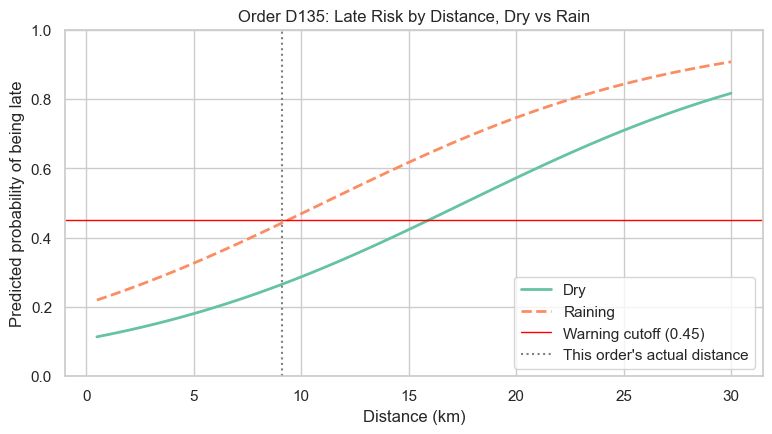

In [21]:
dist_grid = np.linspace(0.5, 30, 60)
fig, ax = plt.subplots(figsize=(9, 4.5))
for rain_flag, label, style in [(0, "Dry", "-"), (1, "Raining", "--")]:
    grid_rows = pd.concat([order] * len(dist_grid)).assign(distance_km=dist_grid, is_raining=rain_flag)
    ax.plot(dist_grid, clf.predict_proba(make_inputs(grid_rows))[:, 1], style, linewidth=2, label=label)
ax.axhline(WARN_CUTOFF, color="red", linewidth=1, label=f"Warning cutoff ({WARN_CUTOFF:.2f})")
ax.axvline(order["distance_km"].iat[0], color="grey", linestyle=":", label="This order's actual distance")
ax.set_title(f"Order {order['delivery_id'].iat[0]}: Late Risk by Distance, Dry vs Rain")
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Predicted probability of being late")
ax.set_ylim(0, 1)
ax.legend()
plt.show()

---
## Part I: Scoring tomorrow's deliveries

In [22]:
incoming = pd.read_csv("deliveries_to_predict.csv")
assert incoming["delivery_id"].is_unique and incoming.notna().all().all()

incoming_p = clf.predict_proba(make_inputs(incoming))[:, 1]
out = incoming[["delivery_id"]].copy()
out["late_probability"] = np.round(incoming_p, 4)
out["predicted_late"] = (incoming_p >= WARN_CUTOFF).astype(int)
out.to_csv("predictions.csv", index=False)

print(f"Saved predictions.csv with {len(out)} rows")
print(f"Orders that will see the warning: {out['predicted_late'].sum()} ({out['predicted_late'].mean():.0%})")
out.sort_values("late_probability", ascending=False).head(10)

Saved predictions.csv with 60 rows
Orders that will see the warning: 19 (32%)


,delivery_id,late_probability,predicted_late
2,D530,0.9502,1
9,D150,0.9072,1
51,D460,0.7969,1
32,D526,0.7569,1
23,D423,0.7483,1
13,D550,0.7219,1
29,D459,0.6939,1
52,D175,0.6449,1
50,D363,0.6238,1
47,D195,0.6125,1


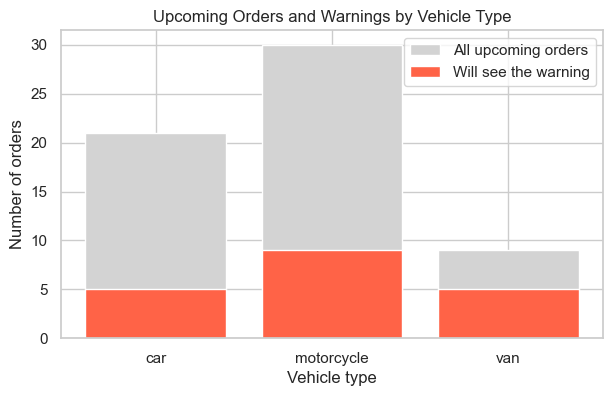

In [23]:
by_vehicle = incoming.assign(warned=out["predicted_late"]).groupby("vehicle_type")["warned"].agg(["sum", "count"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(by_vehicle.index, by_vehicle["count"], color="lightgrey", label="All upcoming orders")
ax.bar(by_vehicle.index, by_vehicle["sum"], color="tomato", label="Will see the warning")
ax.set_title("Upcoming Orders and Warnings by Vehicle Type")
ax.set_xlabel("Vehicle type")
ax.set_ylabel("Number of orders")
ax.legend()
plt.show()

---
# Report to the Delivery Team

**To:** Product and Operations
**From:** Calzado
**Re:** When to show "Heads up! Your order may arrive late."

## The short answer
Show the warning when the model gives an order a **45% or higher** chance of being late. For the 60 orders in the upcoming batch, that means **19 customers (about one in three)** get the heads-up.

## What actually makes an order late?
I looked at 440 finished deliveries. Each statement below compares two orders that are identical except for the one thing named.

* **Rush hour is the number-one problem.** An order sent out in rush hour has a little over **3 times** the odds of being late.
* **Vans struggle.** Compared with a motorcycle, a van has nearly **3 times** the odds of running late. Cars sit in between and are only slightly worse than motorcycles.
* **Rain about doubles the odds** of a late arrival.
* **Every kilometre counts.** Each extra kilometre adds about **13%** to the odds of lateness. Over 10 extra kilometres that compounds to roughly **3.3 times** the odds.
* **Experienced drivers save the day.** Each additional year of driving experience lowers the odds of lateness by about **11%**.
* **Package weight barely matters**: about 8% higher odds per extra kilogram, the weakest effect in the model.

Put together, the riskiest order is a long van trip at rush hour in the rain with a new driver, and that is where the warning will appear most often.

## How I made my decisions
**Checking the data.** All 440 rows were complete and every delivery ID was unique, so nothing was dropped. 40% of past orders were late. That is a fairly common outcome, but not an even split, so I judged the model on how many late orders it catches and how trustworthy its warnings are, not on plain accuracy.

**Splitting fairly.** I split the orders 70% / 15% / 15% into training, validation and test sets, stratified so each keeps the 40% late rate, with `random_state=42` so anyone can reproduce the result. The model learned only from the training orders, I chose the cutoff with the validation orders, and the test orders were used exactly once, at the end.

**Keeping inputs readable.** I left distance, weight and experience in their real units instead of rescaling them, so every coefficient translates straight into "per kilometre" or "per year" language. The only transformation was turning vehicle type into yes/no columns, using the categories found in the training set and motorcycle as the comparison point.

**How well it works.** The model separates late from on-time orders reasonably well (ROC-AUC 0.79 on training and 0.82 on validation, so it is not overfitting). On the untouched test set, at the 0.45 cutoff:
* **Precision 0.63**: when the app shows the warning, the order really is late about 6 times out of 10.
* **Recall 0.58**: the app warns the customer on close to 6 out of 10 late orders.
* Test confusion matrix: 15 late orders caught, 11 missed, 9 unnecessary warnings, 31 correctly left alone.

## Why 0.45 and not the default 0.50?
A cutoff is a trade-off between two complaints: "you warned me for nothing" and "you didn't warn me." I decided that a **missed late order costs about three times as much** as an unnecessary warning, because being blindsided is the exact problem the company asked me to fix. On the 66 validation orders:

| Cutoff | Warnings shown | Unnecessary warnings | Missed late orders | Precision | Recall | Weighted cost |
|---|---|---|---|---|---|---|
| 0.35 | 36 | 15 | 6 | 0.58 | 0.78 | 33 |
| **0.45** | **26** | **6** | **7** | **0.77** | **0.74** | **27** |
| 0.50 | 21 | 4 | 10 | 0.81 | 0.63 | 34 |
| 0.55 | 14 | 1 | 14 | 0.93 | 0.48 | 43 |

* Going from **0.50 down to 0.45** catches 3 more late orders while adding only 2 more unnecessary warnings, a clear win.
* Going further down to **0.35** catches just 1 more late order but adds 9 more false alarms. That is where the warning starts to lose credibility.
* **0.55** produces almost no false alarms, but over half of late orders slip through unannounced.

0.45 had the lowest weighted cost among the candidates and also among every cutoff from 0.05 to 0.95 in my sweep. It does not depend heavily on the exact 3:1 weighting: 0.45 also has the fewest total mistakes (13) of the four options.

## Weather in action
I took order **D135** (a 9.1 km motorcycle trip outside rush hour, with a driver of under half a year's experience). In dry weather its risk is about **27%**; in the rain it rises to about **44%**, landing just under the 0.45 cutoff. One more unfavourable factor, such as a slightly longer trip, would tip it over and trigger the warning. Rain alone can move an ordinary order right up to the edge of a warning.

## Caveats
The test set has only 66 orders, so its scores can swing by several points from sample to sample; the test precision and recall came in lower than on validation for that reason. The model does not know about live traffic, store preparation time or the hour of the day beyond the rush-hour flag. Once the warning is live, the team should log what actually happens and refit the model every few months.

## Recommendation
1. Turn the warning on for orders scoring **0.45 or above**.
2. Review warning accuracy monthly. If customers complain about false alarms, nudge the cutoff up to 0.50; if they complain about surprise delays, move it down toward 0.40.
3. Operationally, avoid sending vans and new drivers on long rush-hour runs whenever there is an alternative.